# Лекция 1. Разведывательный анализ данных

**Дисциплина:** Анализ данных в Python  
**Тема:** Введение в EDA, библиотеки NumPy, Pandas, SciPy

В этом ноутбуке:
- Основы работы с массивами NumPy
- Таблицы Pandas: загрузка, фильтрация, группировка
- Обработка пропусков, дубликатов и выбросов
- Кодирование категориальных признаков
- Масштабирование числовых признаков
- Описательная статистика и статистические тесты (SciPy)

In [ ]:

# ИМПОРТ БИБЛИОТЕК

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка графиков
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

## 1. Основы NumPy

NumPy — базовая библиотека для работы с многомерными массивами.  
Основной объект — `ndarray`. Отличия от списков Python:
- все элементы одного типа;
- векторные операции (без циклов);
- быстрее в разы.

In [2]:
# Создание массивов разными способами
a = np.array([1, 2, 3, 4, 5])              # из списка
b = np.zeros((3, 3))                        # матрица нулей 3x3
c = np.ones((2, 4))                         # матрица единиц 2x4
d = np.arange(0, 10, 2)                     # [0, 2, 4, 6, 8]
e = np.linspace(0, 1, 5)                    # 5 равномерных точек
f = np.random.rand(3, 3)                    # случайные [0,1)
g = np.random.randn(100)                    # нормальное распределение

print('a =', a)
print('b =\n', b)
print('d =', d)
print('e =', e)

a = [1 2 3 4 5]
b =
 [[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
d = [0 2 4 6 8]
e = [0.   0.25 0.5  0.75 1.  ]


In [3]:
# Поэлементные и агрегатные операции
x = np.array([1, 2, 3, 4, 5])

print('Сумма:', x.sum())
print('Среднее:', x.mean())
print('Медиана:', np.median(x))
print('Стд. отклонение:', x.std())
print('Минимум:', x.min(), 'Максимум:', x.max())

# Векторные операции — без циклов
print('x * 2 =', x * 2)
print('x ** 2 =', x ** 2)
print('x + 10 =', x + 10)

Сумма: 15
Среднее: 3.0
Медиана: 3.0
Стд. отклонение: 1.4142135623730951
Минимум: 1 Максимум: 5
x * 2 = [ 2  4  6  8 10]
x ** 2 = [ 1  4  9 16 25]
x + 10 = [11 12 13 14 15]


In [4]:
# Индексация, срезы, булевы маски
x = np.array([1, 2, 3, 4, 5])

print('Первый элемент:', x[0])
print('Последний:', x[-1])
print('Срез [1:4]:', x[1:4])
print('Срез с шагом [::2]:', x[::2])

# Булева маска — выбираем только элементы > 3
mask = x > 3
print('x > 3:', x[mask])

Первый элемент: 1
Последний: 5
Срез [1:4]: [2 3 4]
Срез с шагом [::2]: [1 3 5]
x > 3: [4 5]


In [5]:
# Изменение формы, объединение, разделение
a = np.arange(12)                # [0..11]
b = a.reshape(3, 4)              # матрица 3x4
print('b =\n', b)

c = b.flatten()                  # обратно в одномерный
print('c =', c)

d = b.T                          # транспонирование
print('d =\n', d)

# Объединение
e = np.concatenate([a, a])
print('concat:', e)

# Разделение
parts = np.split(a, 3)
print('split:', parts)

b =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
c = [ 0  1  2  3  4  5  6  7  8  9 10 11]
d =
 [[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]
concat: [ 0  1  2  3  4  5  6  7  8  9 10 11  0  1  2  3  4  5  6  7  8  9 10 11]
split: [array([0, 1, 2, 3]), array([4, 5, 6, 7]), array([ 8,  9, 10, 11])]


## 2. Основы Pandas

Pandas — библиотека для табличных данных.  
Основные структуры: **Series** (одномерный массив с индексами) и **DataFrame** (таблица).

In [6]:
# Загрузка встроенного датасета Titanic (не требует скачивания)
df = sns.load_dataset('titanic')

# Первые 5 строк
print('Первые 5 строк:')
df.head()

Первые 5 строк:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [7]:
# Общая информация о данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [8]:
# Описательные статистики для числовых столбцов
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# Проверка пропусков и дубликатов
print('Пропуски по столбцам:')
print(df.isnull().sum())

print('\nКоличество дубликатов:', df.duplicated().sum())

Пропуски по столбцам:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Количество дубликатов: 107


## 3. Фильтрация и группировка

In [10]:
# Фильтрация по условию
adults = df[df['age'] > 30]
print('Пассажиров старше 30:', len(adults))

# Комбинирование условий: & (и), | (или), ~ (не)
women_1st = df[(df['sex'] == 'female') & (df['pclass'] == 1)]
print('Женщин в 1 классе:', len(women_1st))

# Выбор нескольких столбцов
subset = df[['age', 'fare', 'survived']]
subset.head()

Пассажиров старше 30: 305
Женщин в 1 классе: 94


,age,fare,survived
0,22.0,7.2500,0
1,38.0,71.2833,1
2,26.0,7.9250,1
3,35.0,53.1000,1
4,35.0,8.0500,0


In [11]:
# Группировка и агрегация
# Средняя выживаемость по полу
print('Выживаемость по полу:')
print(df.groupby('sex')['survived'].mean())

# Несколько агрегатов одновременно
print('\nСтатистика стоимости билета по классу:')
print(df.groupby('pclass')['fare'].agg(['mean', 'median', 'std']))

# Группировка по двум признакам
print('\nВыживаемость по полу и классу:')
print(df.groupby(['sex', 'pclass'])['survived'].mean())

Выживаемость по полу:
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

Статистика стоимости билета по классу:
             mean   median        std
pclass                               
1       84.154687  60.2875  78.380373
2       20.662183  14.2500  13.417399
3       13.675550   8.0500  11.778142

Выживаемость по полу и классу:
sex     pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: survived, dtype: float64


## 4. Обработка пропусков

Пропуски — распространённая проблема реальных данных.  
Способы обработки:
- удаление (`dropna`);
- заполнение константой;
- заполнение медианой (числовые) / модой (категориальные);
- интерполяция (для временных рядов).

In [12]:
# Создаём копию, чтобы не портить оригинал
df_clean = df.copy()

# Заполняем пропуски в 'age' медианой
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())

# В 'embarked' — модой (самое частое значение)
df_clean['embarked'] = df_clean['embarked'].fillna(df_clean['embarked'].mode()[0])

# В 'deck' слишком много пропусков — просто удалим столбец
df_clean = df_clean.drop(columns=['deck'])

# Проверяем, что пропусков больше нет в ключевых столбцах
print(df_clean[['age', 'embarked']].isnull().sum())

age         0
embarked    0
dtype: int64


## 5. Обнаружение и обработка выбросов

**Правило межквартильного размаха (IQR):**  
Выброс — значение за пределами `[Q1 − 1.5·IQR; Q3 + 1.5·IQR]`

In [13]:
# Обнаружение выбросов в столбце 'fare' методом IQR
Q1 = df_clean['fare'].quantile(0.25)
Q3 = df_clean['fare'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f'Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}')
print(f'Границы выбросов: [{lower:.2f}; {upper:.2f}]')

outliers = df_clean[(df_clean['fare'] < lower) | (df_clean['fare'] > upper)]
print(f'Найдено выбросов: {len(outliers)}')

Q1=7.91, Q3=31.00, IQR=23.09
Границы выбросов: [-26.72; 65.63]
Найдено выбросов: 116


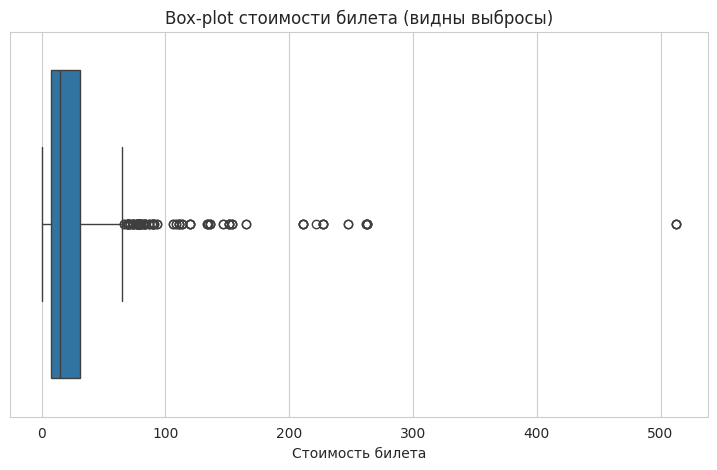

In [14]:
# Визуально посмотрим на выбросы с помощью box-plot
sns.boxplot(x=df_clean['fare'])
plt.title('Box-plot стоимости билета (видны выбросы)')
plt.xlabel('Стоимость билета')
plt.show()

## 6. Кодирование категориальных признаков

ML-алгоритмы работают с числами. Категории надо закодировать:
- **One-Hot Encoding** — каждая категория → отдельный бинарный столбец;
- **Label Encoding** — каждой категории присваивается число (для порядковых);
- **Target Encoding** — категория заменяется средним целевой переменной.

In [15]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

# --- One-Hot Encoding ---
# Превращает 'sex' и 'embarked' в несколько бинарных столбцов
ohe = OneHotEncoder(drop='first', sparse_output=False)
X_ohe = ohe.fit_transform(df_clean[['sex', 'embarked']])

print('One-Hot Encoding:')
print('Форма:', X_ohe.shape)
print('Категории:', ohe.get_feature_names_out())
print(X_ohe[:5])

One-Hot Encoding:
Форма: (891, 3)
Категории: ['sex_male' 'embarked_Q' 'embarked_S']
[[1. 0. 1.]
 [0. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [1. 0. 1.]]


In [16]:
# --- Label Encoding ---
# Подходит, если у категории есть естественный порядок
le = LabelEncoder()
df_clean['sex_label'] = le.fit_transform(df_clean['sex'])

print('Label Encoding для sex:')
print(df_clean[['sex', 'sex_label']].drop_duplicates())

Label Encoding для sex:
      sex  sex_label
0    male          1
1  female          0


## 7. Масштабирование числовых признаков

- **StandardScaler** — приводит к среднему 0 и дисперсии 1;
- **MinMaxScaler** — сжимает в диапазон [0, 1];
- **RobustScaler** — использует медиану и IQR, устойчив к выбросам.

In [17]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Признаки для масштабирования
num_cols = ['age', 'fare']
X_num = df_clean[num_cols].dropna()

# Три варианта масштабирования
std = StandardScaler().fit_transform(X_num)
mm = MinMaxScaler().fit_transform(X_num)
rb = RobustScaler().fit_transform(X_num)

# Сравним статистики до и после
print('Исходные данные:')
print(X_num.describe().loc[['mean', 'std', 'min', 'max']])

print('\nПосле StandardScaler:')
print(pd.DataFrame(std, columns=num_cols).describe().loc[['mean', 'std', 'min', 'max']])

Исходные данные:
            age        fare
mean  29.361582   32.204208
std   13.019697   49.693429
min    0.420000    0.000000
max   80.000000  512.329200

После StandardScaler:
               age          fare
mean  2.272780e-16  3.987333e-18
std   1.000562e+00  1.000562e+00
min  -2.224156e+00 -6.484217e-01
max   3.891554e+00  9.667167e+00


## 8. Описательная статистика и тесты в SciPy

In [18]:
# Сравним возраст выживших и погибших (t-критерий Стьюдента)
survived = df_clean[df_clean['survived'] == 1]['age'].dropna()
died = df_clean[df_clean['survived'] == 0]['age'].dropna()

t_stat, p_value = stats.ttest_ind(survived, died)
print(f't-статистика: {t_stat:.3f}')
print(f'p-value: {p_value:.4f}')

if p_value < 0.05:
    print('→ Различие статистически значимо (p < 0.05)')
else:
    print('→ Различие НЕ значимо (p ≥ 0.05)')

t-статистика: -1.939
p-value: 0.0528
→ Различие НЕ значимо (p ≥ 0.05)


In [19]:
# Проверка нормальности распределения возраста (Shapiro-Wilk)
stat, p = stats.shapiro(df_clean['age'].dropna().sample(500, random_state=42))
print(f'Shapiro-Wilk: W={stat:.3f}, p={p:.4f}')

if p > 0.05:
    print('→ Распределение похоже на нормальное')
else:
    print('→ Распределение НЕ нормальное')

Shapiro-Wilk: W=0.953, p=0.0000
→ Распределение НЕ нормальное


## 9. Разведывательный анализ данных (EDA)

Основные шаги:
1. Описательные статистики.
2. Распределения признаков (гистограммы).
3. Взаимосвязи (корреляции, диаграммы рассеяния).
4. Категориальные данные (столбчатые диаграммы).
5. Проверка гипотез.

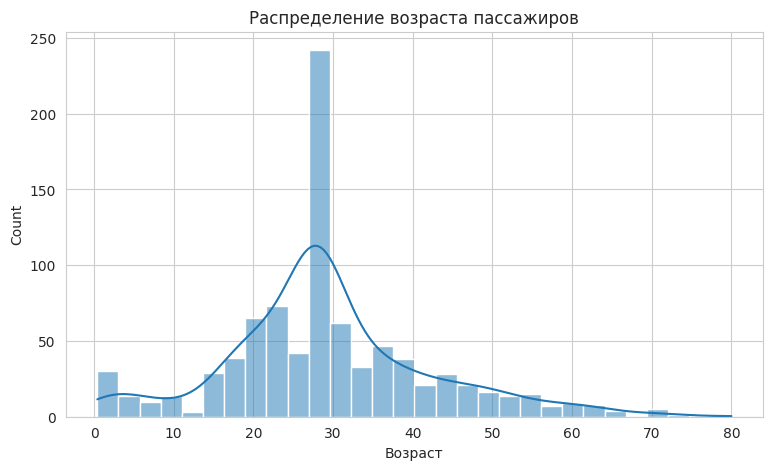

In [20]:
# 1. Распределение возраста
sns.histplot(df_clean['age'], kde=True, bins=30)
plt.title('Распределение возраста пассажиров')
plt.xlabel('Возраст')
plt.show()

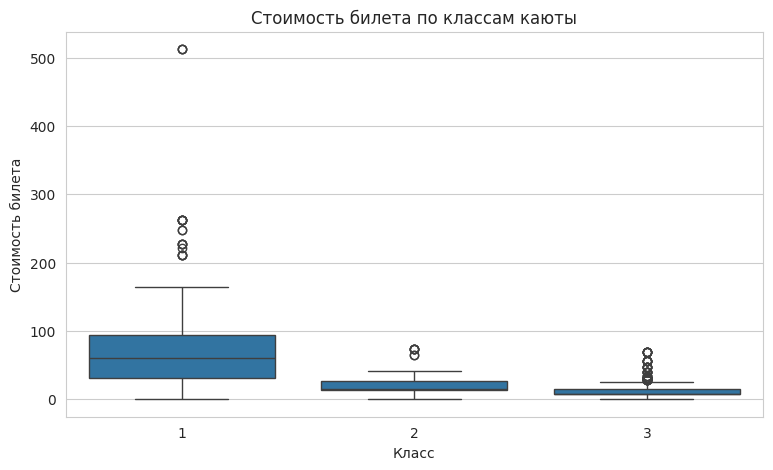

In [21]:
# 2. Стоимость билета по классам (box-plot)
sns.boxplot(data=df_clean, x='pclass', y='fare')
plt.title('Стоимость билета по классам каюты')
plt.xlabel('Класс')
plt.ylabel('Стоимость билета')
plt.show()

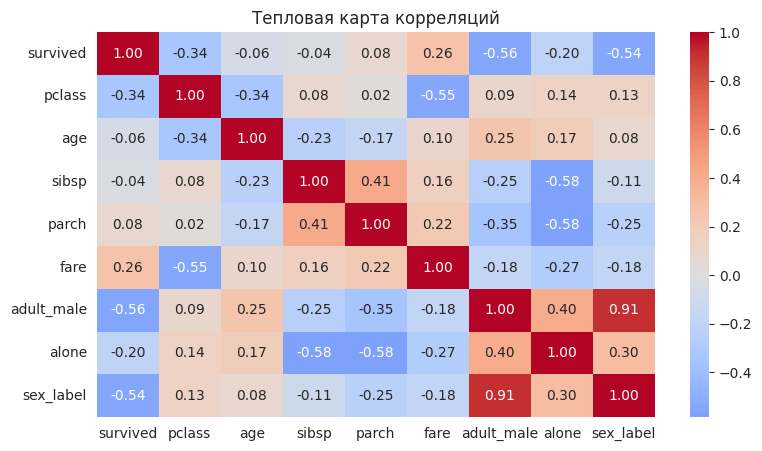

In [22]:
# 3. Тепловая карта корреляций
corr = df_clean.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта корреляций')
plt.show()

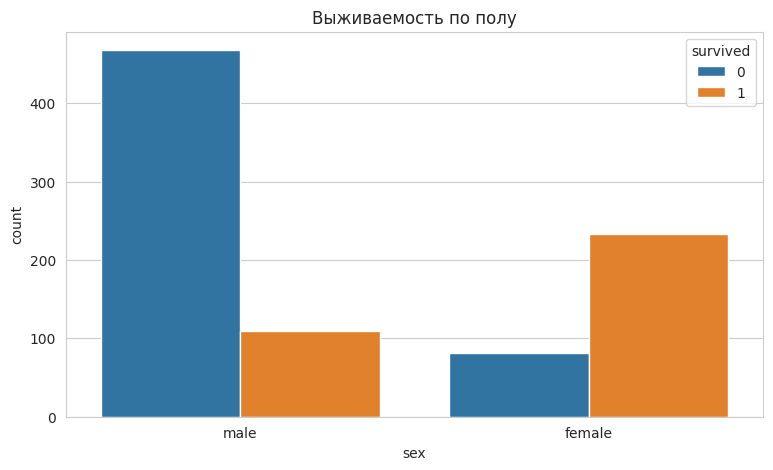

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


In [23]:
# 4. Проверка гипотезы: женщины выживали чаще
sns.countplot(data=df_clean, x='sex', hue='survived')
plt.title('Выживаемость по полу')
plt.show()

# Численно
print(df_clean.groupby('sex')['survived'].mean())

## Выводы по лекции 1

Мы разобрали:
- массивы NumPy и их операции;
- таблицы Pandas, фильтрацию и группировку;
- обработку пропусков, дубликатов и выбросов;
- кодирование категорий и масштабирование;
- статистические тесты и основы EDA.

**Ключевая идея:** качество модели ML напрямую зависит от качества
подготовки данных, а EDA — важнейший этап исследования.